# 1 · Camera calibration

The calibration master is a grid of circles with three larger circles arranged in an "L": the corner of the L is the origin of the reference frame. The images are taken at known distances `z` (`z = file_number · 10 + 50` mm).

A **single model** of the camera is estimated on the points of the views with `z ≤ 350 mm`: projection matrix `P` (3×4), radial distortion (`k1`, `k2`, center) and, as nuisance parameters, the lateral shift of the master in each view (the setup was not perfectly stable). The work is done on points, not on images: no double *undistort* and a single coordinate system all the way to the measurement.

In [1]:
from pathlib import Path

import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA, FIGURES = ROOT / "data", ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

from lightsheet3d.calibration import fit_camera, model_residuals
from lightsheet3d.grid import find_first_valid_circles_grid, find_origin_index
from lightsheet3d.pipeline import PATTERN_MAX, PATTERN_MIN, calibrate_camera

## Grid and origin on one view

pattern 12 rows x 16 columns, 192 centers; origin = center no. 85


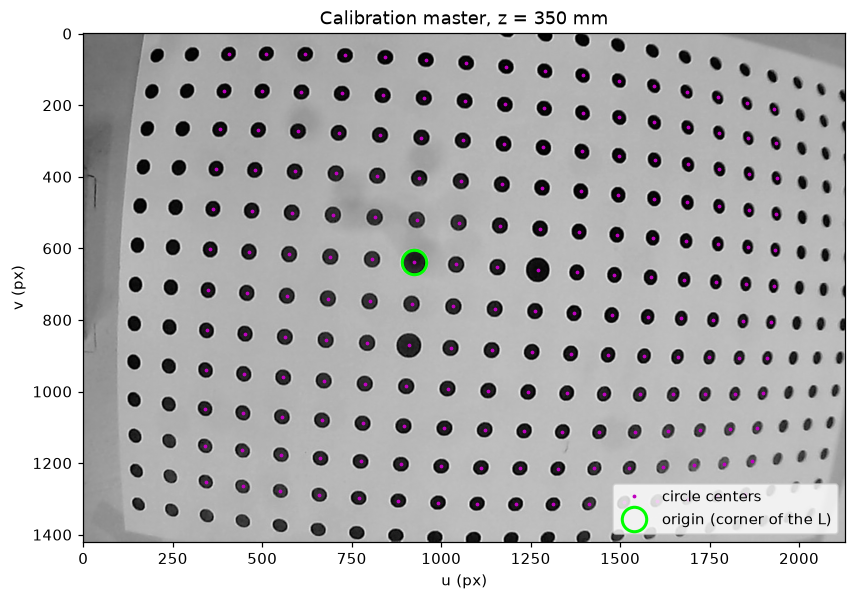

In [2]:
gray = cv.imread(str(DATA / "camera_calibration" / "30_main.jpg"), cv.IMREAD_GRAYSCALE)
pattern, centers = find_first_valid_circles_grid(gray, *PATTERN_MAX, min_size=PATTERN_MIN)
origin = find_origin_index(gray, centers)
print(f"pattern {pattern[1]} rows x {pattern[0]} columns, {len(centers)} centers; origin = center no. {origin}")

fig, ax = plt.subplots(figsize=(9, 6))
ax.imshow(gray, cmap="gray")
ax.plot(*centers.T, "m.", ms=3, label="circle centers")
ax.plot(*centers[origin], "o", mfc="none", mec="lime", ms=16, mew=2, label="origin (corner of the L)")
ax.set(xlabel="u (px)", ylabel="v (px)", title="Calibration master, z = 350 mm")
ax.grid(False); ax.legend(loc="lower right")
fig.savefig(FIGURES / "camera_grid_origin.png", bbox_inches="tight")

## Joint model

In [3]:
camera = calibrate_camera(DATA / "camera_calibration")
model = camera.model
K = model.P[:, :3]
print("views used (z, mm):", sorted(int(z) for z in set(camera.view_ids)), "| discarded:", list(camera.skipped))
print(f"k1 = {model.k[0]:.4f}, k2 = {model.k[1]:.4f}, distortion center = ({model.center[0]:.0f}, {model.center[1]:.0f}) px")
print("camera optical center (mm):", (-np.linalg.solve(K, model.P[:, 3])).round(1))
print("\nestimated lateral shift of the master per view (mm):")
for z, (dx, dy) in zip(model.views, model.offsets):
    print(f"  z = {z:.0f}:  dx = {dx:+5.1f}  dy = {dy:+5.1f}")

views used (z, mm): [300, 310, 320, 330, 340, 350] | discarded: []
k1 = -0.1097, k2 = 0.0110, distortion center = (877, 666) px
camera optical center (mm): [ -8.9 -47.1  16.3]

estimated lateral shift of the master per view (mm):
  z = 300:  dx =  +0.1  dy =  +1.6
  z = 310:  dx =  -0.3  dy =  -2.2
  z = 320:  dx =  -0.7  dy =  -1.8
  z = 330:  dx =  -1.5  dy =  +3.2
  z = 340:  dx =  +5.9  dy =  -0.1
  z = 350:  dx =  +0.0  dy =  +0.0


discarded 9 wrong centers; residual on 1019 points: median 1.64 px, 95th percentile 8.3 px, rms 3.6 px


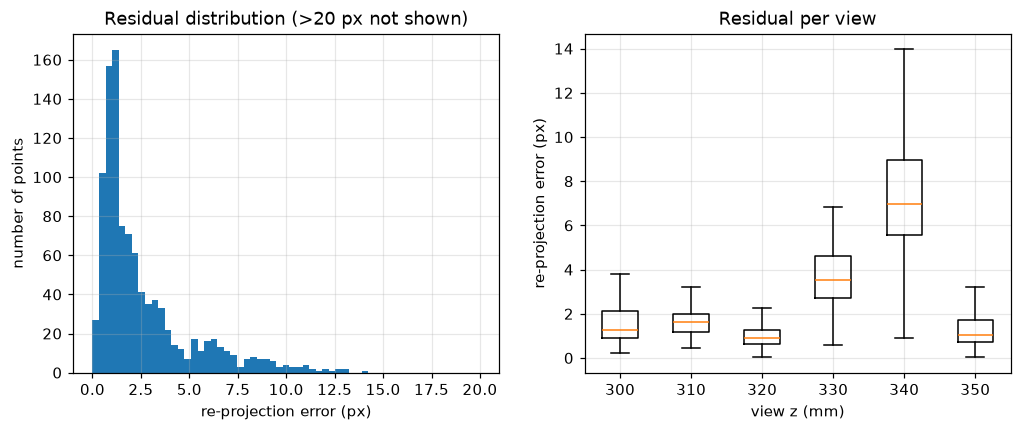

In [4]:
keep = camera.inliers  # wrong centers (residual > 10 times the median) enter neither the fit nor the statistics
res = model_residuals(model, camera.world, camera.image, camera.view_ids)[keep]
print(f"discarded {int((~keep).sum())} wrong centers; residual on {len(res)} points: median {np.median(res):.2f} px, 95th percentile {np.percentile(res, 95):.1f} px, rms {np.sqrt((res**2).mean()):.1f} px")

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 4))
a.hist(res, bins=np.linspace(0, 20, 60)); a.set(xlabel="re-projection error (px)", ylabel="number of points", title="Residual distribution (>20 px not shown)")
b.boxplot([res[camera.view_ids[keep] == z] for z in model.views], showfliers=False, tick_labels=[f"{z:.0f}" for z in model.views])
b.set(xlabel="view z (mm)", ylabel="re-projection error (px)", title="Residual per view")
fig.savefig(FIGURES / "camera_residuals.png", bbox_inches="tight")

## Validation

As required by the assignment, 10% of the points of each view are held out, the model is recalibrated on the rest and the residual is measured on the held-out points (the master shifts are re-estimated on the 90%).

In [5]:
world, image, view_ids = camera.world[keep], camera.image[keep], camera.view_ids[keep]
held_out = np.arange(len(world)) % 10 == 0
m90 = fit_camera(world[~held_out], image[~held_out], view_ids[~held_out], (2130, 1420), reference_view=350)
for name, mask in (("calibration (90%)", ~held_out), ("validation (10%)", held_out)):
    r = model_residuals(m90, world[mask], image[mask], view_ids[mask])
    print(f"{name:20s} median {np.median(r):.2f} px | 95th percentile {np.percentile(r, 95):.1f} px | rms {np.sqrt((r**2).mean()):.1f} px")

calibration (90%)    median 1.66 px | 95th percentile 8.3 px | rms 3.6 px
validation (10%)     median 1.69 px | 95th percentile 8.1 px | rms 3.5 px


**Reading.** The median (~1.6 px, about 0.4 mm on the master) is the representative value; the rms is dominated by a tail of points with larger residuals. The per-view plot shows that the tail comes mostly from the views at z = 330 and 340 mm (median ~3 and ~7 px): a plausible, unverified hypothesis is that in those shots the master also tilted, an effect that the model (lateral shift only) does not describe. The median on the held-out points is practically identical to the calibration one (and the rms is even lower, because the anomalous centers mostly fall in the 90% used for the fit): the model is not overfitting. The physical limit is the stability of the setup, not the algorithm.